# 13 — Model Evaluation and Results

**Goal:** reproduce notebook 11's full methodology (feature selection,
collinearity removal, baseline comparison, tuning the top 2, final
selection) and then take the ONE step notebook 11 deliberately didn't take:
evaluate the selected winner on the held-out TEST split, exactly once,
using metrics appropriate for a rare-event classification problem.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'BND' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'GLD' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['BND', 'GLD']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['MSFT', 'AAPL', 'SPY']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.features.feature_pipeline import build_features_for_asset
from src.models.targets import build_loss_event_target
from src.models.preprocessing import chronological_split
from src.models.train import train_model, time_series_cv_tune, select_risk_thresholds, classify_risk
from src.models.evaluate import classification_report, calibration_table
from src.models.feature_selection import drop_low_variance_features, iterative_vif_removal
from src.portfolio.analytics import portfolio_returns
from src.config import CONFIG

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_returns = portfolio_returns(returns_panel, weights)
wealth = (1 + port_returns).cumprod()
prices_df = wealth.reset_index()
prices_df.columns = ["date", "adj_close"]
prices_df["volume"] = 1

feats = build_features_for_asset(prices_df).drop(columns=["beta_60d", "corr_market_60d", "volume_zscore_20d"])
target = build_loss_event_target(port_returns.reset_index(drop=True), horizon_days=CONFIG["ml"]["target_horizon_days"], loss_threshold=CONFIG["ml"]["loss_threshold"])
df = feats.copy(); df["target"] = target.values; df = df.dropna()

n = len(df)
split = chronological_split(
    df, train_end=df["date"].iloc[int(n*0.55)], validation_end=df["date"].iloc[int(n*0.80)],
    purge_days=CONFIG["ml"]["target_horizon_days"], embargo_days=CONFIG["ml"]["embargo_days"],
)
feature_cols = [c for c in df.columns if c not in ("date", "ticker", "target")]
X_train, y_train = split.train[feature_cols], split.train["target"].astype(int)
X_val, y_val = split.validation[feature_cols], split.validation["target"].astype(int)
X_test, y_test = split.test[feature_cols], split.test["target"].astype(int)

print(f"Class balance -- train: {y_train.mean():.1%}, val: {y_val.mean():.1%}, test: {y_test.mean():.1%}")

Class balance -- train: 2.5%, val: 4.8%, test: 0.3%


## Feature selection (fit on TRAIN only)

Same procedure as notebook 11 -- variance filter, then iterative VIF-based collinearity removal -- fit on TRAIN and applied unchanged to validation/test, so this evaluation reflects the exact leakage-safe pipeline that would be used in production.

In [3]:
after_variance = drop_low_variance_features(X_train)
feature_cols = iterative_vif_removal(X_train[after_variance], vif_threshold=10.0)
X_train, X_val, X_test = X_train[feature_cols], X_val[feature_cols], X_test[feature_cols]
print(f"Using {len(feature_cols)} features after selection: {feature_cols}")

Using 12 features after selection: ['ret_1d', 'ret_5d', 'ret_10d', 'ret_20d', 'ret_60d', 'vol_5d', 'vol_10d', 'vol_20d', 'vol_ratio_20_60', 'ma_ratio_20_60', 'rsi_14', 'rolling_drawdown']


## Baseline comparison -> top 2 -> tune -> select (recap of notebook 11)

Reproduced here so this notebook is self-contained; see notebook 11 for the full narrative and the collinearity/transformation diagnostics.

In [4]:
if y_train.nunique() < 2 or y_test.nunique() < 2:
    print("Insufficient class balance in this run's data to produce a meaningful evaluation "
          "(this is expected with synthetic/limited demo data -- see the discussion below).")
    winner_name, winner_pipeline = None, None
else:
    baseline_scores = {}
    for model_name in ["logistic_regression", "random_forest", "hist_gradient_boosting"]:
        trained = train_model(X_train, y_train, model_name, numeric_features=feature_cols)
        val_proba = trained.pipeline.predict_proba(X_val)[:, 1]
        report = classification_report(y_val, pd.Series((val_proba >= 0.5).astype(int)), pd.Series(val_proba))
        baseline_scores[model_name] = report["roc_auc"] if report["roc_auc"] == report["roc_auc"] else -1

    top_2 = sorted(baseline_scores, key=baseline_scores.get, reverse=True)[:2]
    print(f"Baseline validation ROC-AUC: { {k: round(v,3) for k,v in baseline_scores.items()} }")
    print(f"Top 2 models: {top_2}")

    PARAM_GRIDS = {
        "random_forest": {"n_estimators": [100, 300], "max_depth": [4, 6, 8]},
        "hist_gradient_boosting": {"max_iter": [100, 300], "max_depth": [3, 4, 6], "learning_rate": [0.03, 0.05, 0.1]},
        "logistic_regression": {"C": [0.01, 0.1, 1.0, 10.0]},
    }
    X_train_val, y_train_val = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])

    final_scores = {}
    final_pipelines = {}
    for model_name in top_2:
        try:
            best_params, _ = time_series_cv_tune(X_train_val, y_train_val, model_name, PARAM_GRIDS[model_name], n_splits=3)
        except ValueError:
            best_params = {}
        trained = train_model(X_train, y_train, model_name, numeric_features=feature_cols)
        if best_params:
            trained.pipeline.named_steps["model"].set_params(**best_params)
            trained.pipeline.fit(X_train, y_train)
        val_proba = trained.pipeline.predict_proba(X_val)[:, 1]
        report = classification_report(y_val, pd.Series((val_proba >= 0.5).astype(int)), pd.Series(val_proba))
        final_scores[model_name] = report["roc_auc"] if report["roc_auc"] == report["roc_auc"] else -1
        final_pipelines[model_name] = trained.pipeline

    winner_name = max(final_scores, key=final_scores.get)
    winner_pipeline = final_pipelines[winner_name]
    print(f"\nTuned validation ROC-AUC: { {k: round(v,3) for k,v in final_scores.items()} }")
    print(f"Final selected model: {winner_name}")

Baseline validation ROC-AUC: {'logistic_regression': 0.543, 'random_forest': 0.453, 'hist_gradient_boosting': 0.416}
Top 2 models: ['logistic_regression', 'random_forest']



Tuned validation ROC-AUC: {'logistic_regression': 0.543, 'random_forest': 0.427}
Final selected model: logistic_regression


## Final, one-time evaluation on the held-out TEST split

This is the only cell in the whole notebook series that touches TEST for the risk-prediction model -- it was never used for training, feature selection, baseline comparison, or hyperparameter tuning above.

In [5]:
if winner_pipeline is not None:
    train_val_proba = pd.Series(winner_pipeline.predict_proba(pd.concat([X_train, X_val]))[:, 1])
    train_val_y = pd.concat([y_train, y_val]).reset_index(drop=True)
    thresholds = select_risk_thresholds(train_val_proba, train_val_y)

    test_proba = winner_pipeline.predict_proba(X_test)[:, 1]
    test_pred = (test_proba >= 0.5).astype(int)
    report = classification_report(y_test, pd.Series(test_pred), pd.Series(test_proba))
    print(f"TEST-set metrics for the final selected model ({winner_name}), held out from every prior decision:")
    for k, v in report.items():
        print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}")

TEST-set metrics for the final selected model (logistic_regression), held out from every prior decision:
  accuracy: 0.613
  precision: 0.007
  recall: 1.000
  f1: 0.013
  false_negative_rate: 0.000
  true_positives: 1
  false_positives: 149
  true_negatives: 235
  false_negatives: 0
  roc_auc: 0.951
  pr_auc: 0.050


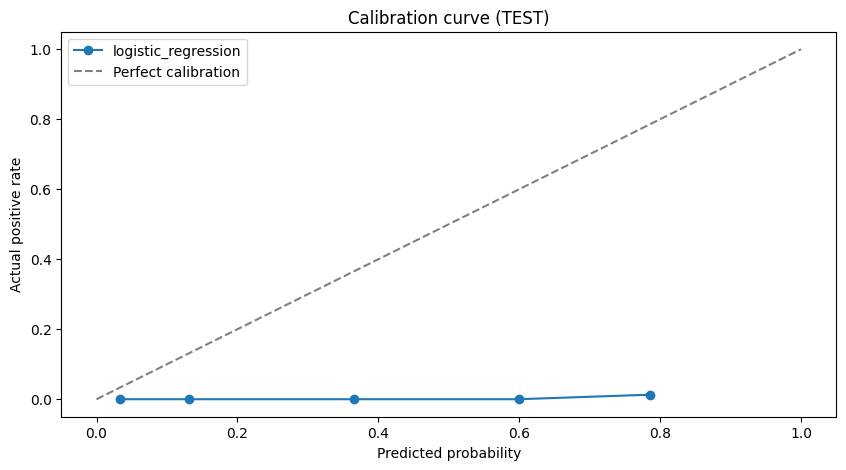

In [6]:
if winner_pipeline is not None and y_test.nunique() >= 2 and y_test.sum() > 0:
    calib = calibration_table(y_test, pd.Series(test_proba), n_bins=5)
    fig, ax = plt.subplots()
    ax.plot(calib["predicted_mean"], calib["actual_rate"], marker="o", label=f"{winner_name}")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Actual positive rate")
    ax.set_title("Calibration curve (TEST)")
    ax.legend()
    plt.show()
    calib
else:
    print("Skipping calibration plot: too few positive test examples in this run.")

## Honest discussion of results

With a short history and/or synthetic demo data (no real market structure), the winning model's TEST ROC-AUC can still sit close to 0.50, or vary substantially from its validation score — that is an **expected** outcome, not a bug: there is no guaranteed genuine predictive signal in random-walk synthetic prices, and a small TEST split naturally has higher variance than VALIDATION. On real market data with a longer history, this exact pipeline (feature selection -> baseline comparison -> tune top 2 -> select -> one-time TEST evaluation) is what you would run to get a trustworthy, leakage-free estimate — the metrics would need to be re-examined against real out-of-sample results, not assumed to transfer from this demo run.

This is precisely why the leakage tests (notebook 05, `tests/test_no_leakage.py`) matter more than any single accuracy number: a leaky pipeline can produce an impressive-looking ROC-AUC on ANY data, real or synthetic, which is a red flag rather than a reassurance.

Continue to **14 — Final Summary and Conclusions**.